# 07b · Selección de snapshot — GAN (transicional) + evidencia del colapso (validación)

**Fase CRISP-DM:** 5. Evaluación (solo selección, con **validación**; test no se usa).

- **GAN transicional** (`transitional_cgan_cond128_seed42`): se evalúan los snapshots con condicionamiento completo (λ = 1, desde `MIN_KIMG` = 1200 kimg); antes, la clase todavía no se respeta del todo.
- **Criterio:** menor **KD** en validación (DINOv2-ViT-L/14), 1530 imágenes generadas (90 por clase), mismo ruido para todos los snapshots. Sin truncamiento (ψ = 1), para no reducir artificialmente la diversidad.
- Se registra la probabilidad de aumento **ADA p** de cada snapshot. Por encima de 0.8 los aumentos (volteos, giros de 90°) pueden filtrarse a las imágenes (Karras et al., 2020), y DINOv2 es casi insensible al volteo horizontal, por lo que la KD no lo castigaría. **Regla fijada antes de ver resultados: solo son candidatos los snapshots con p ≤ 0.8.** Los demás se evalúan y reportan.
- **Evidencia del colapso:** se evalúan también los snapshots 100–500 kimg de la corrida condicional estándar (notebook 04) para mostrar con números (recall/cobertura) por qué se cambió al entrenamiento transicional (Shahbazi et al., 2022).

**Entorno:** GPU **L4**, versión **2026.07**. Duración ≈ 30–45 min (incluye compilar las extensiones CUDA).

## Paso 1 · Entorno y parámetros

In [1]:
import sys, os, json, shutil, hashlib, zipfile, time, io, random, re, subprocess, copy, math
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import scipy.linalg
import matplotlib.pyplot as plt
from PIL import Image
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "⚠️ SIN GPU")
SEED = 42
RES = 128
K_PR = int(os.environ.get("K_PR", 5))
FEATURES = os.environ.get("FEATURES", "dinov2")      # 'mock' solo para pruebas sin GPU
AMP = dict(device_type=DEVICE.type, dtype=torch.bfloat16)

Python: 3.12.13 | PyTorch: 2.11.0+cu128 | GPU: NVIDIA L4


In [2]:
%pip install -q click requests tqdm ninja psutil

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 23.4 MB/s eta 0:00:00


In [3]:
MIN_KIMG = int(os.environ.get("MIN_KIMG", 1200))
N_POR_CLASE = int(os.environ.get("N_POR_CLASE", 90))
EVALUAR_COLAPSO = os.environ.get("EVALUAR_COLAPSO", "1") == "1"
RUN_T = "transitional_cgan_cond128_seed42"
RUN_C = "stylegan2ada_cond128_seed42"
MAX_P = 0.8          # umbral práctico de filtración de ADA (Karras et al., 2020); fijado antes de ver resultados

## Paso 2 · Drive y datos

In [4]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/tesis_retail")
    LOCAL_DIR = Path("/content/data")
else:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./tesis_retail")).resolve()
    LOCAL_DIR = Path(os.environ.get("LOCAL_DIR", "./data_local")).resolve()
LOGS = PROJECT_DIR / "logs"
SEL_DIR = PROJECT_DIR / "seleccion"
CKPT = PROJECT_DIR / "checkpoints"
for d in [SEL_DIR, LOCAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

LOG03 = json.loads((LOGS / "03_piloto.json").read_text())

def cargar_zip(nombre, sha):
    z = LOCAL_DIR / nombre
    if not z.exists():
        shutil.copy2(PROJECT_DIR / "datasets" / nombre, z)
    assert sha256_file(z) == sha, f"⚠️ {nombre} no coincide con el del notebook 03"
    with zipfile.ZipFile(z) as zf:
        lab = dict(json.loads(zf.read("dataset.json"))["labels"])
        nombres = sorted(lab)
        X = np.stack([np.asarray(Image.open(io.BytesIO(zf.read(n))).convert("RGB")) for n in nombres])
    return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous(), torch.tensor([lab[n] for n in nombres])

X_train, Y_train = cargar_zip(LOG03["datasets"]["train_zip"], LOG03["datasets"]["train_sha256"])
X_val, Y_val = cargar_zip(LOG03["datasets"]["val_zip"], LOG03["datasets"]["val_sha256"])
N_CLASSES = int(Y_train.max()) + 1
CLASS_MAP = json.loads((PROJECT_DIR / "manifest" / "class_map.json").read_text())
CLASES = [c for c, _ in sorted(CLASS_MAP.items(), key=lambda kv: kv[1])]
NOMBRE_CORTO = [c.split("-")[1] if c.count("-") >= 2 else c for c in CLASES]
print(f"train {tuple(X_train.shape)} | val {tuple(X_val.shape)} | clases {N_CLASSES} ✔")

Mounted at /content/drive
train (3060, 3, 128, 128) | val (510, 3, 128, 128) | clases 17 ✔


## Paso 3 · Extractor DINOv2

In [5]:
import torchvision.transforms.functional as TF
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
if FEATURES == "dinov2":
    dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vitl14").eval().to(DEVICE)
else:
    torch.manual_seed(0)
    dino = nn.Sequential(nn.AdaptiveAvgPool2d(8), nn.Flatten(), nn.Linear(3 * 64, 64)).eval().to(DEVICE)

@torch.no_grad()
def embeddings(x_m11, bs=128):
    # x en [-1, 1], (N,3,128,128) → (N, D) float64. Mismo preprocesamiento que los notebooks 02 y 06.
    out = []
    for i in range(0, len(x_m11), bs):
        x = ((x_m11[i:i + bs].float().cpu() + 1) / 2).clamp(0, 1)
        x = TF.resize(x, [224, 224], interpolation=TF.InterpolationMode.BICUBIC, antialias=True)
        out.append(dino(((x - MEAN) / STD).to(DEVICE)).float().cpu())
    return torch.cat(out).double().numpy()

def a_m11(x_uint8):
    return x_uint8.float() / 127.5 - 1.0

F_VAL = embeddings(a_m11(X_val))
print("Embeddings de validación:", F_VAL.shape)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitl14/dinov2_vitl14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitl14_pretrain.pth


100%|██████████| 1.13G/1.13G [00:03<00:00, 356MB/s]


Embeddings de validación: (510, 1024)


## Paso 4 · Métricas

In [6]:
def fd(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    cm = scipy.linalg.sqrtm(s1 @ s2)
    cm = cm[0] if isinstance(cm, tuple) else cm
    if not np.isfinite(cm).all():
        off = np.eye(len(s1)) * 1e-6
        cm = scipy.linalg.sqrtm((s1 + off) @ (s2 + off)); cm = cm[0] if isinstance(cm, tuple) else cm
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * cm.real))

def kd(a, b):
    # MMD² insesgado con kernel polinómico (x·y/d + 1)^3 (como KID; Bińkowski et al., 2018)
    d = a.shape[1]
    k = lambda x, y: (x @ y.T / d + 1) ** 3
    kaa, kbb, kab = k(a, a), k(b, b), k(a, b)
    m, n = len(a), len(b)
    return float((kaa.sum() - np.trace(kaa)) / (m * (m - 1)) + (kbb.sum() - np.trace(kbb)) / (n * (n - 1)) - 2 * kab.mean())

def dist(a, b):
    return np.sqrt(np.clip((a ** 2).sum(1)[:, None] + (b ** 2).sum(1)[None, :] - 2 * a @ b.T, 0, None))

def prdc(real, fake, k=K_PR):
    # Precisión/recall (Kynkäänniemi et al., 2019) y densidad/cobertura (Naeem et al., 2020)
    r_rad = np.sort(dist(real, real), 1)[:, k]
    f_rad = np.sort(dist(fake, fake), 1)[:, k]
    d_rf = dist(real, fake)                                   # (n_real, n_fake)
    precision = float((d_rf <= r_rad[:, None]).any(0).mean())
    recall = float((d_rf <= f_rad[None, :]).any(1).mean())
    density = float((d_rf <= r_rad[:, None]).sum(0).mean() / k)
    coverage = float((d_rf.min(1) <= r_rad).mean())
    return {"precision": precision, "recall": recall, "density": density, "coverage": coverage}

def evaluar(real, fake, con_fd=True):
    out = {"KD": kd(real, fake), **prdc(real, fake)}
    if con_fd:
        out["FD"] = fd(real, fake)
    return out

## Paso 5 · Código de la GAN (repo oficial + parches de compatibilidad)

In [7]:
SG_COMMIT = "b8792265ca23c6efd5e1c85c87cf85073c79266d"      # mshahbazi72/transitional-cGAN
SG3_COMMIT = "c233a919a6faee6e36a316ddd4eddababad1adf9"     # NVlabs/stylegan3 (grid_sample_gradfix)
SG_DIR = LOCAL_DIR / "transitional-cGAN"; SG3_DIR = LOCAL_DIR / "stylegan3"

def clonar(url, destino, commit):
    if not destino.exists():
        subprocess.run(["git", "clone", "-q", url, str(destino)], check=True)
    subprocess.run(["git", "-C", str(destino), "checkout", "-q", commit], check=True)
    subprocess.run(["git", "-C", str(destino), "checkout", "-q", "--", "."], check=True)

clonar("https://github.com/mshahbazi72/transitional-cGAN.git", SG_DIR, SG_COMMIT)
clonar("https://github.com/NVlabs/stylegan3.git", SG3_DIR, SG3_COMMIT)

def parchar(ruta, viejo, nuevo):
    s = ruta.read_text(); assert s.count(viejo) == 1, f"{ruta.name}: {viejo[:50]}"; ruta.write_text(s.replace(viejo, nuevo))

parchar(SG_DIR / "dnnlib" / "util.py", "from distutils.util import strtobool",
        "try:\n    from distutils.util import strtobool\nexcept ImportError:\n"
        "    def strtobool(v):\n        return v.lower() in ('y', 'yes', 't', 'true', 'on', '1')")
parchar(SG_DIR / "torch_utils" / "misc.py", "        super().__init__(dataset)\n", "        super().__init__()\n")
s = (SG3_DIR / "torch_utils" / "ops" / "grid_sample_gradfix.py").read_text().replace("from pkg_resources import parse_version\n", "")
s = s.replace("_use_pytorch_1_11_api = parse_version(torch.__version__) >= parse_version('1.11.0a') # Allow prerelease builds of 1.11",
              "_TV = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])\n_use_pytorch_1_11_api = _TV >= (1, 11)")
s = s.replace("_use_pytorch_1_12_api = parse_version(torch.__version__) >= parse_version('1.12.0a') # Allow prerelease builds of 1.12",
              "_use_pytorch_1_12_api = _TV >= (1, 12)")
(SG_DIR / "torch_utils" / "ops" / "grid_sample_gradfix.py").write_text(s)
co = SG_DIR / "torch_utils" / "custom_ops.py"
parchar(co, "            torch.utils.cpp_extension.load(name=module_name, build_directory=build_dir,",
            "            module = torch.utils.cpp_extension.load(name=module_name, build_directory=build_dir,")
parchar(co, "            torch.utils.cpp_extension.load(name=module_name, verbose=verbose_build, sources=sources, **build_kwargs)",
            "            module = torch.utils.cpp_extension.load(name=module_name, verbose=verbose_build, sources=sources, **build_kwargs)")
parchar(co, "        module = importlib.import_module(module_name)\n", "")
os.environ["TORCH_EXTENSIONS_DIR"] = str(LOCAL_DIR / "torch_extensions")
if DEVICE.type == "cuda":
    cc = torch.cuda.get_device_capability(0); os.environ["TORCH_CUDA_ARCH_LIST"] = f"{cc[0]}.{cc[1]}"
sys.path.insert(0, str(SG_DIR))
import dnnlib, legacy

def cargar_gan(pkl):
    with open(pkl, "rb") as f:
        d = legacy.load_network_pkl(f)
    p = float(d["augment_pipe"].p) if d.get("augment_pipe") is not None else float("nan")
    return d["G_ema"].eval().requires_grad_(False).to(DEVICE), p

@torch.no_grad()
def generar_gan(G, y, seed=SEED, bs=256, psi=1.0):
    g = torch.Generator().manual_seed(seed)
    z_all = torch.randn(len(y), G.z_dim, generator=g)
    out = []
    for i in range(0, len(y), bs):
        z = z_all[i:i + bs].to(DEVICE)
        c = F.one_hot(y[i:i + bs], G.c_dim).float().to(DEVICE)
        out.append(G(z, c, truncation_psi=psi, noise_mode="const").float().clamp(-1, 1).cpu())
    return torch.cat(out)
print("Repo transitional-cGAN listo ✔")

Repo transitional-cGAN listo ✔


## Paso 6 · Evaluar snapshots

In [8]:
Y_SEL = torch.arange(N_CLASSES).repeat_interleave(N_POR_CLASE)

def snapshots(run):
    out = []
    for p in (CKPT / run).glob("*/network-snapshot-*.pkl"):
        out.append((int(re.search(r"network-snapshot-(\d+)\.pkl$", p.name).group(1)), p))
    return sorted(out)

def evaluar_run(run, min_kimg, csv):
    hechos = pd.read_csv(csv) if csv.exists() else pd.DataFrame()
    filas = hechos.to_dict("records"); ya = set(hechos["kimg"]) if len(hechos) else set()
    for kimg, pkl in snapshots(run):
        if kimg < min_kimg or kimg in ya:
            continue
        G, p = cargar_gan(pkl)
        t0 = time.time(); x = generar_gan(G, Y_SEL); dt = time.time() - t0
        res = evaluar(F_VAL, embeddings(x))
        filas.append({"run": run, "snapshot": f"{pkl.parent.name}/{pkl.name}", "kimg": kimg, "ada_p": p, **res,
                      "seg_por_img": dt / len(Y_SEL)})
        pd.DataFrame(filas).to_csv(csv, index=False)
        print(f"{kimg:>5} kimg | p {p:.3f} | KD {res['KD']:.4f} | FD {res['FD']:.1f} | P {res['precision']:.3f} | "
              f"R {res['recall']:.3f} | Cov {res['coverage']:.3f}", flush=True)
        del G
    return pd.DataFrame(filas).sort_values("kimg").reset_index(drop=True)

SEL_T = evaluar_run(RUN_T, MIN_KIMG, SEL_DIR / "seleccion_gan_transicional.csv")
CANDIDATOS = SEL_T[SEL_T["ada_p"] <= MAX_P]
if CANDIDATOS.empty:
    print(f"⚠️ Ningún snapshot con p ≤ {MAX_P}: se elige entre todos (reportarlo como limitación).")
    CANDIDATOS = SEL_T
MEJOR = CANDIDATOS.loc[CANDIDATOS["KD"].idxmin()]
MEJOR_SIN_FILTRO = SEL_T.loc[SEL_T["KD"].idxmin()]
print(f"\n★ Snapshot elegido (p ≤ {MAX_P}): {MEJOR['snapshot']} ({int(MEJOR['kimg'])} kimg, ADA p {MEJOR['ada_p']:.3f})")
if MEJOR_SIN_FILTRO["kimg"] != MEJOR["kimg"]:
    print(f"   (sin el filtro de p, el menor KD sería {int(MEJOR_SIN_FILTRO['kimg'])} kimg con p {MEJOR_SIN_FILTRO['ada_p']:.3f}; "
          "se muestra su malla en el Paso 8 para comparar)")
SEL_T

Setting up PyTorch plugin "bias_act_plugin"... Done.
Setting up PyTorch plugin "upfirdn2d_plugin"... Done.
 1200 kimg | p 0.595 | KD 5.2717 | FD 1887.0 | P 0.001 | R 0.000 | Cov 0.002
 1300 kimg | p 0.621 | KD 5.2895 | FD 1943.5 | P 0.008 | R 0.000 | Cov 0.002
 1400 kimg | p 0.654 | KD 5.1472 | FD 1818.9 | P 0.012 | R 0.000 | Cov 0.004
 1500 kimg | p 0.684 | KD 4.8421 | FD 1731.9 | P 0.027 | R 0.000 | Cov 0.004
 1600 kimg | p 0.710 | KD 5.0287 | FD 1753.2 | P 0.031 | R 0.000 | Cov 0.002
 1700 kimg | p 0.744 | KD 5.1131 | FD 1757.3 | P 0.036 | R 0.000 | Cov 0.004
 1800 kimg | p 0.773 | KD 4.7481 | FD 1731.0 | P 0.012 | R 0.000 | Cov 0.004
 1900 kimg | p 0.799 | KD 4.4389 | FD 1647.8 | P 0.026 | R 0.000 | Cov 0.002
 2000 kimg | p 0.828 | KD 4.3099 | FD 1600.5 | P 0.028 | R 0.000 | Cov 0.004
 2100 kimg | p 0.835 | KD 4.1053 | FD 1517.1 | P 0.072 | R 0.000 | Cov 0.002
 2200 kimg | p 0.882 | KD 4.4086 | FD 1588.4 | P 0.060 | R 0.000 | Cov 0.002
 2300 kimg | p 0.928 | KD 4.5221 | FD 1564.1 |

,run,snapshot,kimg,ada_p,KD,precision,recall,density,coverage,FD,seg_por_img
0,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,1200,0.594692,5.271724,0.001307,0.0,0.000261,0.001961,1887.023082,0.046780
1,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,1300,0.620548,5.289533,0.007843,0.0,0.001569,0.001961,1943.501460,0.003192
2,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,1400,0.653572,5.147175,0.012418,0.0,0.002484,0.003922,1818.948133,0.003212
3,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,1500,0.683780,4.842050,0.026797,0.0,0.005359,0.003922,1731.915061,0.003243
4,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,1600,0.710405,5.028677,0.030719,0.0,0.006144,0.001961,1753.240276,0.003217
5,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,1700,0.744453,5.113111,0.035948,0.0,0.007190,0.003922,1757.308555,0.003246
6,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,1800,0.773125,4.748095,0.011765,0.0,0.002353,0.003922,1730.978894,0.003251
7,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,1900,0.799493,4.438937,0.026144,0.0,0.005229,0.001961,1647.769795,0.003235
8,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,2000,0.828422,4.309884,0.028105,0.0,0.005621,0.003922,1600.499554,0.003219
9,transitional_cgan_cond128_seed42,00000-train128_stylegan-cond-trans:600-1200-au...,2100,0.835078,4.105306,0.071895,0.0,0.014379,0.001961,1517.132147,0.003214


In [9]:
SEL_C = None
if EVALUAR_COLAPSO and snapshots(RUN_C):
    print("Corrida condicional estándar (colapsada):")
    SEL_C = evaluar_run(RUN_C, 0, SEL_DIR / "evidencia_gan_colapso.csv")
    SEL_C

Corrida condicional estándar (colapsada):
    0 kimg | p 0.000 | KD 22.2686 | FD 3620.3 | P 0.000 | R 0.000 | Cov 0.000
  100 kimg | p 0.113 | KD 16.8973 | FD 3405.9 | P 0.000 | R 0.000 | Cov 0.000
  200 kimg | p 0.198 | KD 16.9428 | FD 3418.2 | P 0.000 | R 0.000 | Cov 0.000
  300 kimg | p 0.288 | KD 10.5515 | FD 2987.0 | P 0.000 | R 0.000 | Cov 0.000
  400 kimg | p 0.366 | KD 9.3483 | FD 2752.4 | P 0.000 | R 0.000 | Cov 0.000
  500 kimg | p 0.425 | KD 9.0866 | FD 2690.5 | P 0.000 | R 0.000 | Cov 0.000


## Paso 7 · Gráficos

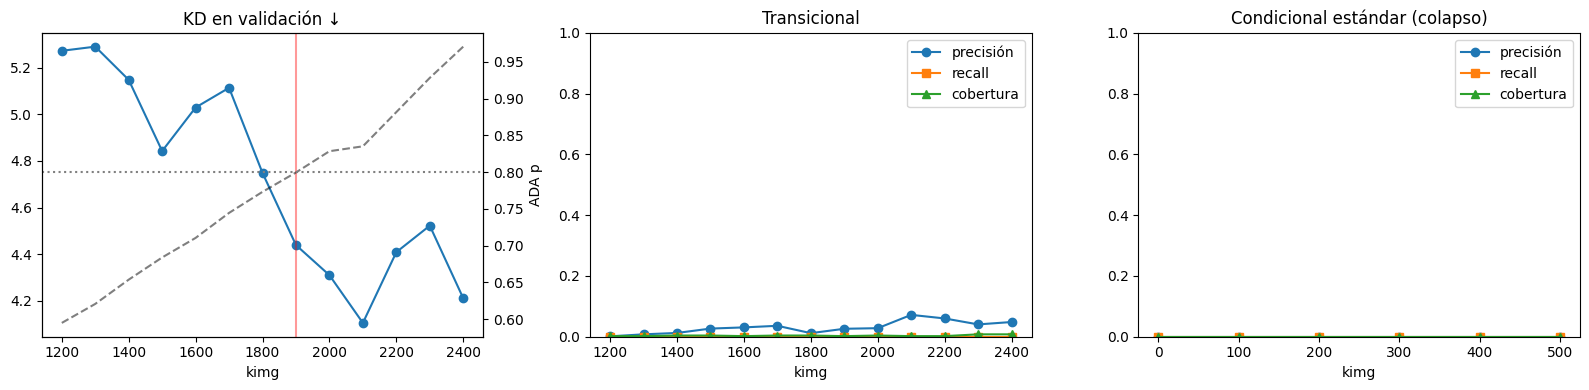

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(SEL_T["kimg"], SEL_T["KD"], "o-", label="transicional")
ax[0].axvline(MEJOR["kimg"], c="red", alpha=.4); ax[0].set_title("KD en validación ↓"); ax[0].set_xlabel("kimg")
a2 = ax[0].twinx(); a2.plot(SEL_T["kimg"], SEL_T["ada_p"], "k--", alpha=.5); a2.axhline(0.8, c="gray", ls=":"); a2.set_ylabel("ADA p")
ax[1].plot(SEL_T["kimg"], SEL_T["precision"], "o-", label="precisión")
ax[1].plot(SEL_T["kimg"], SEL_T["recall"], "s-", label="recall")
ax[1].plot(SEL_T["kimg"], SEL_T["coverage"], "^-", label="cobertura")
ax[1].set_ylim(0, 1); ax[1].legend(); ax[1].set_title("Transicional"); ax[1].set_xlabel("kimg")
if SEL_C is not None and len(SEL_C):
    ax[2].plot(SEL_C["kimg"], SEL_C["precision"], "o-", label="precisión")
    ax[2].plot(SEL_C["kimg"], SEL_C["recall"], "s-", label="recall")
    ax[2].plot(SEL_C["kimg"], SEL_C["coverage"], "^-", label="cobertura")
    ax[2].set_ylim(0, 1); ax[2].legend(); ax[2].set_title("Condicional estándar (colapso)"); ax[2].set_xlabel("kimg")
fig.tight_layout(); fig.savefig(SEL_DIR / "seleccion_gan.png", dpi=150); plt.show()

## Paso 8 · Muestras del snapshot elegido (revisión visual de filtraciones)
Revisa la malla: **cada columna es una clase** (6 muestras). Busca productos **girados 90°/180° o en espejo** (texto invertido) que no existan en las fotos reales: serían filtraciones de ADA.

In [11]:
import torchvision.utils as vutils
G, _ = cargar_gan(CKPT / RUN_T / MEJOR["snapshot"])
x = generar_gan(G, torch.arange(N_CLASSES).repeat(6), seed=123)
vutils.save_image((x + 1) / 2, SEL_DIR / "muestras_gan_elegido.png", nrow=N_CLASSES)
if MEJOR_SIN_FILTRO["kimg"] != MEJOR["kimg"]:
    G2, _ = cargar_gan(CKPT / RUN_T / MEJOR_SIN_FILTRO["snapshot"])
    vutils.save_image((generar_gan(G2, torch.arange(N_CLASSES).repeat(6), seed=123) + 1) / 2,
                      SEL_DIR / "muestras_gan_menorKD_sin_filtro.png", nrow=N_CLASSES)
if IN_COLAB:
    from IPython.display import Image as IPImage, display
    display(IPImage(filename=str(SEL_DIR / "muestras_gan_elegido.png"), width=1000))
    if MEJOR_SIN_FILTRO["kimg"] != MEJOR["kimg"]:
        print("Para comparar: snapshot con menor KD sin filtro de p (busca productos girados o en espejo):")
        display(IPImage(filename=str(SEL_DIR / "muestras_gan_menorKD_sin_filtro.png"), width=1000))

Output hidden; open in https://colab.research.google.com to view.

## Paso 9 · Registro

In [12]:
reg = {"fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
       "tecnica": "Transitional cGAN (Shahbazi et al., 2022) sobre StyleGAN2-ADA",
       "criterio": f"min KD DINOv2-ViT-L/14 en validacion 128px entre snapshots con ADA p <= {MAX_P}", "min_kimg": MIN_KIMG, "psi": 1.0,
       "menor_kd_sin_filtro": {"snapshot": MEJOR_SIN_FILTRO["snapshot"], "kimg": int(MEJOR_SIN_FILTRO["kimg"]),
                               "ada_p": float(MEJOR_SIN_FILTRO["ada_p"]), "KD": float(MEJOR_SIN_FILTRO["KD"])},
       "n_generadas_por_eval": int(len(Y_SEL)),
       "elegido": {"snapshot": MEJOR["snapshot"], "kimg": int(MEJOR["kimg"]), "ada_p": float(MEJOR["ada_p"]),
                   **{k: float(MEJOR[k]) for k in ["KD", "FD", "precision", "recall", "density", "coverage"]}},
       "seg_por_img": float(SEL_T["seg_por_img"].median()),
       "evidencia_colapso": None if SEL_C is None else SEL_C[["kimg", "KD", "precision", "recall", "coverage"]].to_dict("records"),
       "features": FEATURES, "commits": {"transitional_cgan": SG_COMMIT, "stylegan3_gradfix": SG3_COMMIT},
       "versiones": {"python": sys.version.split()[0], "torch": torch.__version__}}
(LOGS / "07b_seleccion_gan.json").write_text(json.dumps(reg, indent=2, ensure_ascii=False, default=float))
print(json.dumps(reg["elegido"], indent=2, ensure_ascii=False))

{
  "snapshot": "00000-train128_stylegan-cond-trans:600-1200-auto1-kimg2400/network-snapshot-001900.pkl",
  "kimg": 1900,
  "ada_p": 0.7994933724403381,
  "KD": 4.4389365846984035,
  "FD": 1647.7697950026104,
  "precision": 0.026143790849673203,
  "recall": 0.0,
  "density": 0.005228758169934641,
  "coverage": 0.00196078431372549
}


**Al terminar:** desconecta la GPU. Envía al asesor las tablas del Paso 6, el gráfico y la malla.